<a href="https://colab.research.google.com/github/shammun/gis-map-tutorials/blob/main/tutorials/gis_styles/05_spilhaus_ocean_colab.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**One ocean.** Makes the poster and the video of sea-surface temperature and sea ice through 2025 on a map cut through the continents.

This is the executed notebook (outputs kept). The same recipe as a script: `05_spilhaus_ocean.py`; for Google Colab: `05_spilhaus_ocean_colab.ipynb` (the badge opens it).

[Gallery](https://shammun.github.io/gis-map-tutorials/) · [this recipe as a web page](https://shammun.github.io/gis-map-tutorials/tutorials/05_spilhaus_ocean.html) · [repository](https://github.com/shammun/gis-map-tutorials) · Map created by Shammunul Islam

# 5 · The ocean as one body of water (Spilhaus projection) with a linked chart

**The idea.** Most world maps keep the continents whole and cut the ocean at the edges. The Spilhaus
projection does the opposite: it is cut through the continents, so every ocean is part of one connected sheet
of water. An ocean field (temperature, currents, sea ice, chlorophyll) then reads as one system. Under or beside
the map, a small chart of a few numbers from the same data carries the playhead.

**This map.** Sea-surface temperature and sea ice through 2025 (NOAA OISST v2.1) and the sea-ice extent of
each hemisphere (NSIDC Sea Ice Index).

Steps: 1 data → 2 the projection → 3 sample the fields through it → 4 colours, ice and land →
5 the linked chart → 6 the finished frame → 7 the animation.

<div style="background:#FFF3E0;border:3px solid #E65100;border-left:14px solid #E65100;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#E65100;font-size:19px;font-weight:bold">CHANGE IF YOU LIKE — RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">Settings</div>
</div>

Everything you may want to change is in this one cell. The checks at the bottom **stop** the notebook with a plain
message if a setting cannot work, before anything slow starts.

`MODE = "FAST"` (the default, one to three minutes; right for Google Colab) writes the poster at 1920 × 1080 px and a short
preview clip of the animation at 960 × 540 px. `MODE = "FULL"` writes the poster at 3840 × 2160 px and the whole
animation at 1920 × 1080 px (several minutes).

In [1]:
import os
import sys

MODE = "FULL" if "--full" in sys.argv else os.environ.get("GIS_MODE", "FAST")   # "FAST" (preview) or "FULL" (poster size, whole animation)
OUT_DIR = os.environ.get("GIS_OUT", "")          # output folder; "" = /content/out on Google Colab, ./out anywhere else
POSTER_DAY = 258                                 # the day of the poster: 0 = 1 January ... 364; 258 = 16 September

from gismaps import nb                           # helpers: data loader, show(), video(), STOP checks, PASS / FAIL

nb.stop_unless(MODE in ("FAST", "FULL"), f"MODE = {MODE!r} must be FAST or FULL")
nb.stop_unless(0 <= POSTER_DAY <= 364, f"POSTER_DAY = {POSTER_DAY} must be a day of the year, 0 to 364")
import pyproj                                    # the Spilhaus projection arrived in PROJ 9.6 (pyproj 3.7.1 or newer)
nb.stop_unless(tuple(int(v) for v in pyproj.proj_version_str.split(".")[:2]) >= (9, 6),
               f"PROJ {pyproj.proj_version_str} has no Spilhaus projection: pip install -U \"pyproj>=3.7.1\"")
POSTER_SCALE = 1.0 if MODE == "FAST" else 2.0    # the design size is 1920 x 1080; the poster is saved at this multiple
OUT = nb.out_dir(OUT_DIR)
print(f"settings OK | mode: {MODE} | output folder: {OUT} | poster {int(1920 * POSTER_SCALE)} x {int(1080 * POSTER_SCALE)} px")

settings OK | mode: FAST | output folder: out | poster 1920 x 1080 px


<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">1 · The data</div>
</div>

Sea-surface temperature and sea-ice concentration on the 1st and 16th of each month of 2025 at 0.5° (NOAA OISST
v2.1, public domain) and the daily sea-ice extent of both hemispheres (NSIDC Sea Ice Index v4), in one small file.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cmocean

from gismaps.styles import common as C, spilhaus      # the map-style code of this repository

print("PROJ", pyproj.proj_version_str, "(Spilhaus needs 9.6 or newer)")
data = nb.load("oisst_2025")                # 24 snapshots (1st and 16th of each month) on 0.5 degrees
print("snapshots:", len(data["date"]), "|", data["date"][0], "...", data["date"][-1])

PROJ 9.8.1 (Spilhaus needs 9.6 or newer)
snapshots: 24 | 2025-01-01 ... 2025-12-16


<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">2 · The projection</div>
</div>

PROJ knows it as `+proj=spilhaus` (since version 9.6). The whole world fills a square about 23,500 km on a
side in projected metres. Its two opposite corners are one point each on land: 30°N 115°E in China and 30°S 65°W in Argentina. `MapGrid`
gives, for every pixel of that square, the longitude and latitude it shows.

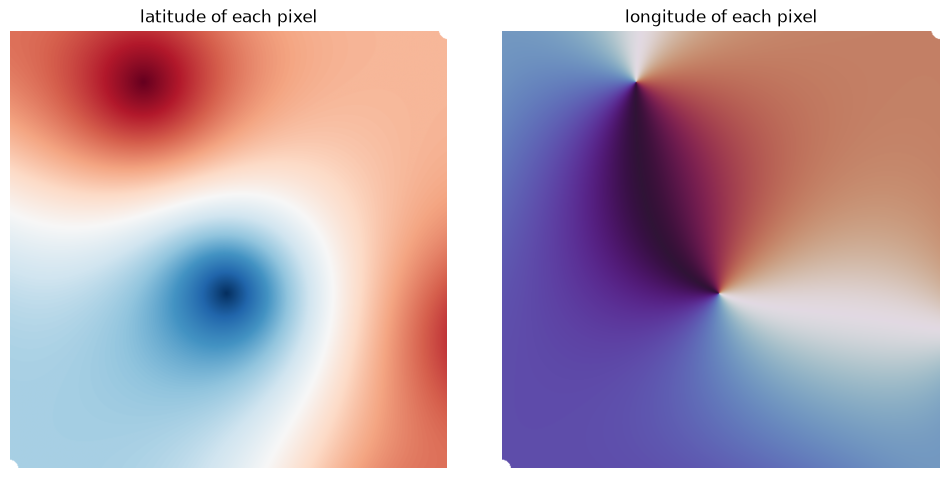

In [3]:
grid = spilhaus.spilhaus_grid(1000)
plon, plat = grid.lonlat()
fig, axs = plt.subplots(1, 2, figsize=(10, 4.8))
axs[0].imshow(plat, cmap="RdBu_r"); axs[0].set_title("latitude of each pixel")
axs[1].imshow(plon, cmap="twilight"); axs[1].set_title("longitude of each pixel")
for a in axs:
    a.axis("off")
plt.tight_layout(); plt.show()

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">3 · Sample the fields through the projection</div>
</div>

We never "re-project polygons" (they would tear at the cuts). We go the other way: each pixel asks the data
grid for its value (`grid.sample`, bilinear, wrapping in longitude). The land mask is a plain lat/lon raster
of Natural Earth sampled the same way, so it also survives the cuts.

In [4]:
k = 17                                                     # 16 September
sst = data["sst_c100"][k].astype(np.float32) / 100.0
sst[data["sst_c100"][k] == -9999] = np.nan
ice = data["ice_pct"][k] / 100.0
ice = np.where(np.nan_to_num(sst, nan=9) <= 1.5, ice, 0)   # drop stray "ice" in water too warm for it
sst_px = grid.sample(sst, data["lat"], data["lon"], wrap=True)
ice_px = np.nan_to_num(grid.sample(ice, data["lat"], data["lon"], wrap=True))
print("ocean pixels:", int(np.isfinite(sst_px).sum()), "of", grid.w * grid.h)

ocean pixels: 497460 of 1000000


<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">4 · Colours, ice and land</div>
</div>

Temperature uses `cmocean.thermal` from −2 to 30 °C. Sea ice is laid on top in pale blue to white where
at least 15 % of the sea is covered (the usual threshold for "ice extent"). Land is a quiet dark grey:
on this map the land is the background.

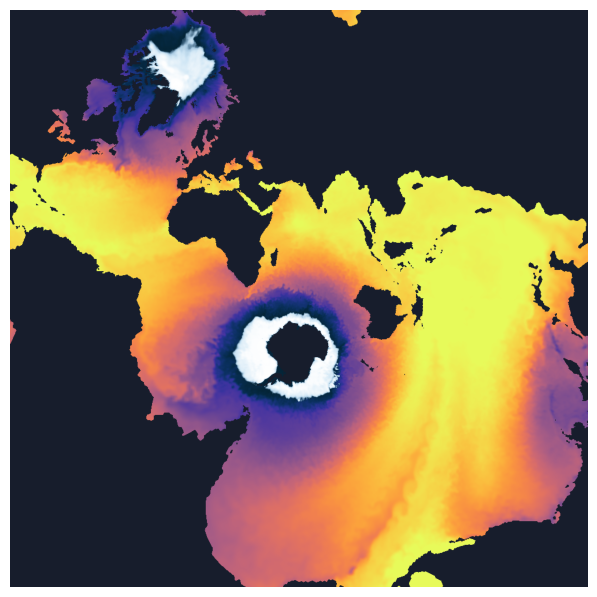

In [5]:
rgb = C.colourise(sst_px, cmocean.cm.thermal, -2, 30)
rgb = C.over(rgb, spilhaus.ICE(np.clip((ice_px - 0.15) / 0.85, 0, 1))[..., :3], np.clip((ice_px - 0.15) / 0.25, 0, 1))
rgb = C.over(rgb, C.rgb("#171d2c"), ~np.isfinite(sst_px) * 1.0)
plt.figure(figsize=(7.5, 7.5)); plt.imshow(rgb); plt.axis("off"); plt.show()

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">5 · The linked chart: which numbers?</div>
</div>

The chart shows the sea-ice **extent** (area of sea with at least 15 % ice) of each hemisphere. We take it from
the NSIDC Sea Ice Index, the reference series, and not from the OISST ice field: summing OISST's ice gives
extents 1 to 3.5 million km² too large in the south. The check is printed below; a linked chart must
be as trustworthy as the map.

In [6]:
doy = np.array([np.datetime64(d) - np.datetime64(str(d)[:4] + "-01-01") for d in data["date"]]).astype(int)
print(" date        NSIDC N  OISST N   NSIDC S  OISST S   (million km2)")
for j in (0, 4, 8, 12, 17, 22):
    print(f" {data['date'][j]}   {data['extent_n'][doy[j]]:5.1f}   {data['oisst_extent_n'][j]:5.1f}"
          f"     {data['extent_s'][doy[j]]:5.1f}   {data['oisst_extent_s'][j]:5.1f}")

 date        NSIDC N  OISST N   NSIDC S  OISST S   (million km2)
 2025-01-01    12.4    13.2       6.9     9.8
 2025-03-01    13.8    15.5       2.0     5.5
 2025-05-01    13.4    13.1       7.8     8.5
 2025-07-01     9.0     9.2      13.6    14.8
 2025-09-16     4.7     4.5      17.8    19.2
 2025-12-01     9.9     9.3      12.3    15.4


<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">6 · The finished frame</div>
</div>


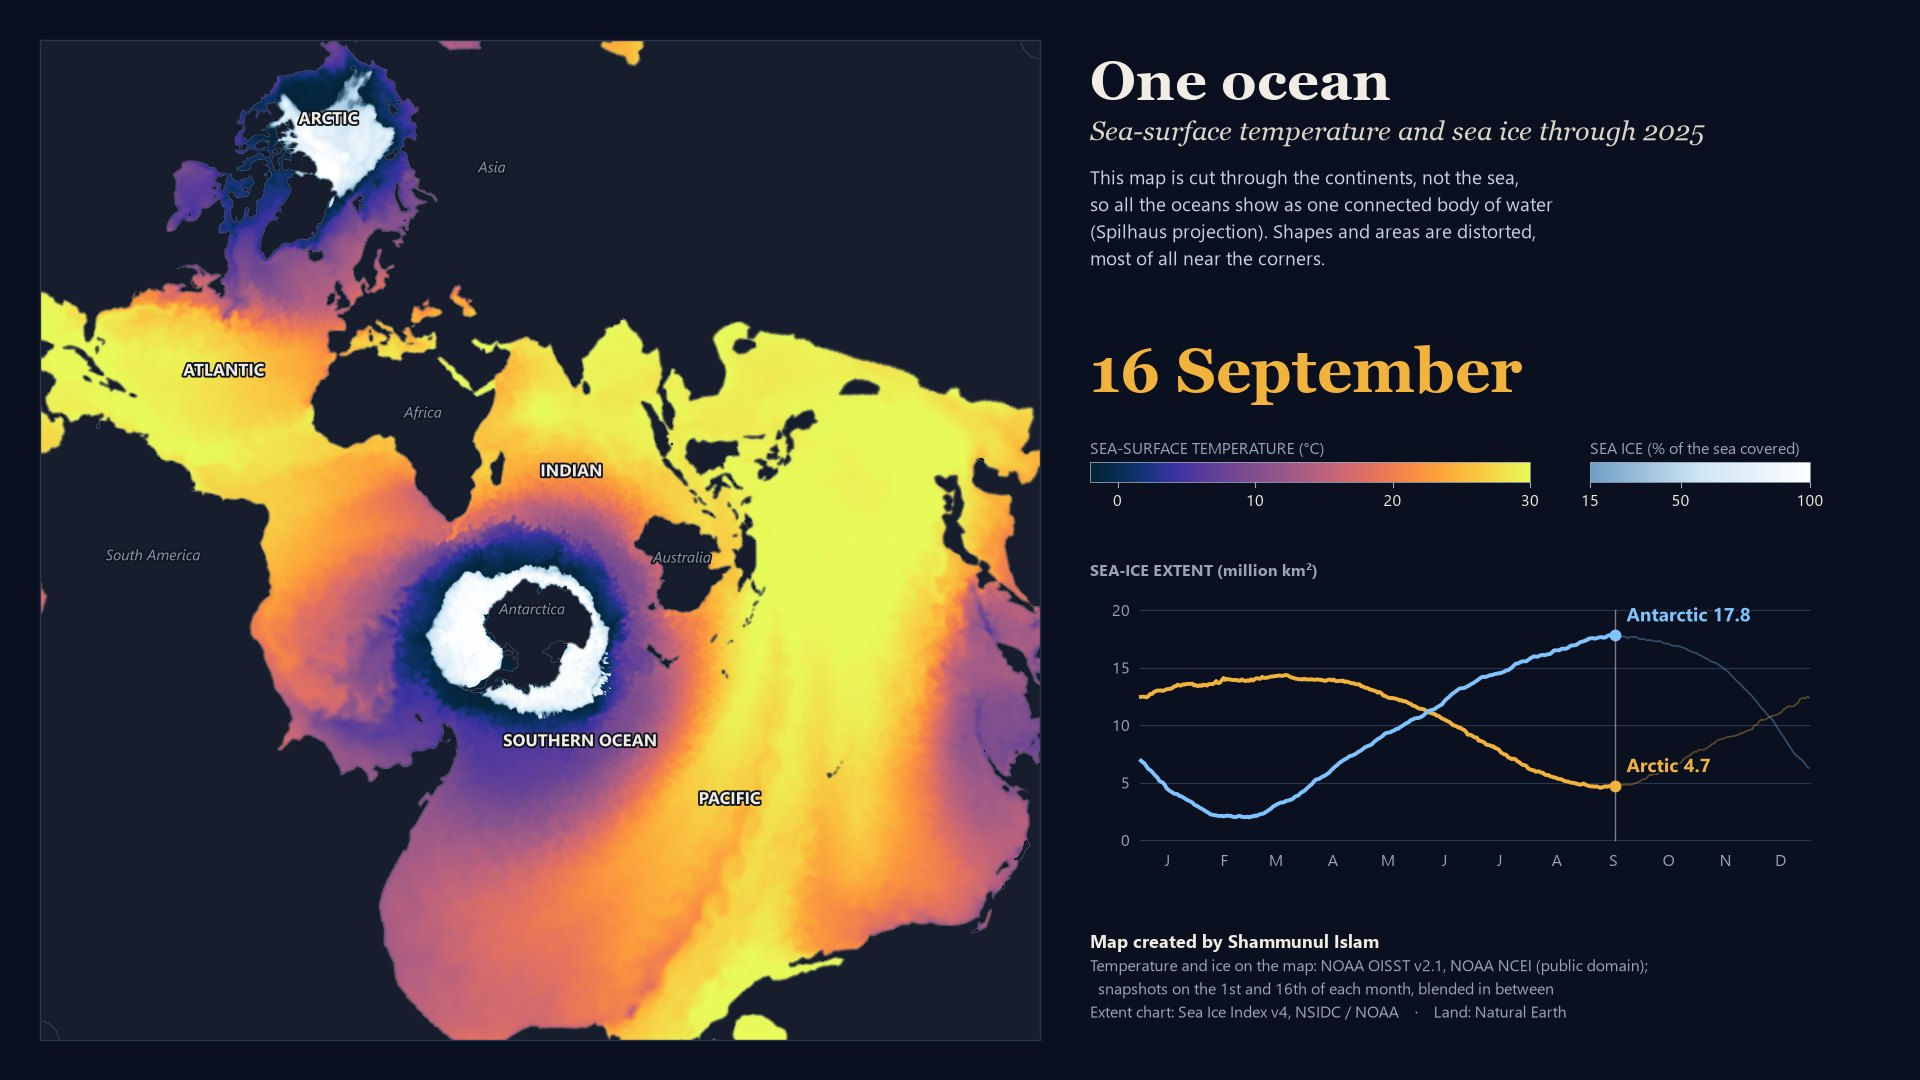

In [7]:
ocean = spilhaus.OceanYear(data)
poster = ocean.poster(OUT / "spilhaus_ocean.png", day=float(POSTER_DAY), scale=POSTER_SCALE)      # 16 September with the default setting
nb.show(poster)

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN — A SHORT PREVIEW IN FAST MODE, THE WHOLE ANIMATION IN FULL MODE</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">7 · The animation</div>
</div>

The 24 snapshots are blended linearly in time, 1.5 days per frame; the chart is daily.

In [8]:
if MODE == "FULL":                               # the whole animation, 1920 x 1080 px
    movie = ocean.animate(OUT / "spilhaus_ocean.mp4", OUT / "frames_05")
else:                                            # a short preview: every 6th frame, 960 x 540 px, 12 frames a second
    movie = C.preview(ocean.animate, OUT / "spilhaus_ocean_preview.mp4", OUT / "frames_05", thin=6)
nb.video(movie)

<div style="background:#E8F5E9;border:3px solid #2E7D32;border-left:14px solid #2E7D32;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#2E7D32;font-size:19px;font-weight:bold">RUN — PASS OR FAIL FOR EVERY OUTPUT</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">Check the outputs</div>
</div>

The last cell checks that every output exists and is what it should be, and prints PASS or FAIL per check.

In [9]:
size = (int(1920 * POSTER_SCALE), int(1080 * POSTER_SCALE))
checks = [
    ("the poster exists", poster.exists()),
    (f"the poster is {size[0]} x {size[1]} px", nb.image_size(poster) == size),
    ("24 snapshots of the year", len(data["date"]) == 24),
    ("the ocean fills a large part of the square", float(np.isfinite(sst_px).mean()) > 0.3),
    ("Arctic sea ice is smallest in September", 235 <= int(np.argmin(data["extent_n"])) <= 280),
]
if not os.environ.get("GIS_PART"):               # (GIS_PART marks a frame worker of the parallel FULL render)
    checks.append(("the movie exists and is not empty", movie is not None and movie.exists() and movie.stat().st_size > 20_000))
nb.verify(checks)

PASS - the poster exists
PASS - the poster is 1920 x 1080 px
PASS - 24 snapshots of the year
PASS - the ocean fills a large part of the square
PASS - Arctic sea ice is smallest in September
PASS - the movie exists and is not empty

All 6 checks passed.


<div style="background:#E3F2FD;border:3px solid #1565C0;border-left:14px solid #1565C0;border-radius:6px;padding:12px 16px;margin:8px 0;color:#1b1b1b">
<div style="color:#1565C0;font-size:19px;font-weight:bold">ON GOOGLE COLAB — ONE ZIP OF THE OUTPUTS</div>
<div style="font-size:16px;font-weight:bold;margin-top:4px">Download (Google Colab)</div>
</div>

On Colab this zips the pictures and movies of the output folder and offers them as one download; anywhere else it
only says where they are.

In [10]:
nb.download(OUT)

33 output file(s) in the folder out/
